In [10]:

import pandas as pd
import numpy as np

from pathlib import Path
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [14]:
file_path = Path("../data/processed/ted_talks_cleaned.csv")

df = pd.read_csv("c:\\Users\\bhava\\OneDrive\\Desktop\\TED TALKS RECOMMADATION\\data\\processed_output\\ted_talks_cleaned.csv")

print("Dataset Shape:", df.shape)

display(df.head())

print("\nDataset Columns:")
print(df.columns.tolist())

Dataset Shape: (3921, 24)


,talk_id,title,speaker_1,all_speakers,occupations,about_speakers,views,recorded_date,published_date,event,...,topics,related_talks,url,description,transcript,title_clean,description_clean,transcript_clean,topics_clean,combined_text
0,1,Al Gore sobre cómo evitar la crisis climática,Al Gore,{0: 'Al Gore'},{0: ['climate advocate']},{0: 'Nobel Laureate Al Gore focused the world’...,3523396,2006-02-25,2006-06-27,TED2006,...,"['alternative energy', 'cars', 'climate change...","{243: 'New thinking on the climate crisis', 54...",https://www.ted.com/talks/al_gore_averting_the...,Con el mismo humor y humanidad que irradió en ...,Muchas gracias Chris. Y es en verdad un gran h...,al gore sobre c mo evitar la crisis clim tica,con el mismo humor y humanidad que irradi en u...,muchas gracias chris y es en verdad un gran ho...,alternative energy cars climate change culture...,al gore sobre c mo evitar la crisis clim tica ...
1,7,"David Pogue dice ""La Simplicidad Vende""",David Pogue,{0: 'David Pogue'},{0: ['technology columnist']},{0: 'David Pogue is the personal technology co...,1920803,2006-02-24,2006-06-27,TED2006,...,"['computers', 'entertainment', 'interface desi...","{1725: '10 top time-saving tech tips', 2274: '...",https://www.ted.com/talks/david_pogue_simplici...,"El columnista del New York Times, David Pogue,...","Hola contestadora automática, mi vieja amiga. ...",david pogue dice la simplicidad vende,el columnista del new york times david pogue a...,hola contestadora autom tica mi vieja amiga ri...,computers entertainment interface design media...,david pogue dice la simplicidad vende el colum...
2,53,Un recorrido por la renovación urbana de la ma...,Majora Carter,{0: 'Majora Carter'},{0: ['activist for environmental justice']},{0: 'Majora Carter redefined the field of envi...,2664029,2006-02-26,2006-06-27,TED2006,...,"['MacArthur grant', 'activism', 'business', 'c...",{1041: '3 stories of local eco-entrepreneurshi...,https://www.ted.com/talks/majora_carter_greeni...,"En una charla altamente emotiva, la activista ...","Si están presentes aquí hoy, y estoy muy conte...",un recorrido por la renovaci n urbana de la ma...,en una charla altamente emotiva la activista g...,si est n presentes aqu hoy y estoy muy content...,macarthur grant activism business cities envir...,un recorrido por la renovaci n urbana de la ma...
3,66,Ken Robinson dice que las escuelas matan la cr...,Sir Ken Robinson,{0: 'Sir Ken Robinson'},"{0: ['author', 'educator']}","{0: ""Creativity expert Sir Ken Robinson challe...",65052534,2006-02-25,2006-06-27,TED2006,...,"['children', 'creativity', 'culture', 'dance',...","{865: 'Bring on the learning revolution!', 173...",https://www.ted.com/talks/sir_ken_robinson_do_...,Sir Ken Robinson plantea de manera entretenida...,"Buenos días. ¿Cómo están? Ha sido increíble, ¿...",ken robinson dice que las escuelas matan la cr...,sir ken robinson plantea de manera entretenida...,buenos d as c mo est n ha sido incre ble verda...,children creativity culture dance education pa...,ken robinson dice que las escuelas matan la cr...
4,92,Hans Rosling nos muestra las mejores estadísti...,Hans Rosling,{0: 'Hans Rosling'},{0: ['global health expert; data visionary']},"{0: 'In Hans Rosling’s hands, data sings. Glob...",14501766,2006-02-22,2006-06-27,TED2006,...,"['Africa', 'Asia', 'Google', 'demo', 'economic...","{2056: ""Own your body's data"", 2296: 'A visual...",https://www.ted.com/talks/hans_rosling_the_bes...,Una manera única de presentar datos. Con la en...,"Hace unos 10 años, emprendí la tarea de enseña...",hans rosling nos muestra las mejores estad sti...,una manera nica de presentar datos con la ener...,hace unos 10 a os emprend la tarea de ense ar ...,africa asia google demo economics global issue...,hans rosling nos muestra las mejores estad sti...



Dataset Columns:
['talk_id', 'title', 'speaker_1', 'all_speakers', 'occupations', 'about_speakers', 'views', 'recorded_date', 'published_date', 'event', 'native_lang', 'available_lang', 'comments', 'duration', 'topics', 'related_talks', 'url', 'description', 'transcript', 'title_clean', 'description_clean', 'transcript_clean', 'topics_clean', 'combined_text']


In [15]:
# Standardize column names
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print(df.columns.tolist())

['talk_id', 'title', 'speaker_1', 'all_speakers', 'occupations', 'about_speakers', 'views', 'recorded_date', 'published_date', 'event', 'native_lang', 'available_lang', 'comments', 'duration', 'topics', 'related_talks', 'url', 'description', 'transcript', 'title_clean', 'description_clean', 'transcript_clean', 'topics_clean', 'combined_text']


In [16]:
# Change these names if your dataset uses different column names

title_col = "title"
tags_col = "tags"
description_col = "description"
transcript_col = "transcript"

required_columns = [
    title_col,
    tags_col,
    description_col,
    transcript_col
]

for col in required_columns:
    if col in df.columns:
        print(col, "is available")
    else:
        print(col, "is not available")

title is available
tags is not available
description is available
transcript is available


In [18]:
print("Dataset Columns:")
print(df.columns.tolist())

Dataset Columns:
['talk_id', 'title', 'speaker_1', 'all_speakers', 'occupations', 'about_speakers', 'views', 'recorded_date', 'published_date', 'event', 'native_lang', 'available_lang', 'comments', 'duration', 'topics', 'related_talks', 'url', 'description', 'transcript', 'title_clean', 'description_clean', 'transcript_clean', 'topics_clean', 'combined_text', 'exp1_text']


In [19]:
display(df.head())

,talk_id,title,speaker_1,all_speakers,occupations,about_speakers,views,recorded_date,published_date,event,...,related_talks,url,description,transcript,title_clean,description_clean,transcript_clean,topics_clean,combined_text,exp1_text
0,1,Al Gore sobre cómo evitar la crisis climática,Al Gore,{0: 'Al Gore'},{0: ['climate advocate']},{0: 'Nobel Laureate Al Gore focused the world’...,3523396,2006-02-25,2006-06-27,TED2006,...,"{243: 'New thinking on the climate crisis', 54...",https://www.ted.com/talks/al_gore_averting_the...,Con el mismo humor y humanidad que irradió en ...,Muchas gracias Chris. Y es en verdad un gran h...,al gore sobre c mo evitar la crisis clim tica,con el mismo humor y humanidad que irradi en u...,muchas gracias chris y es en verdad un gran ho...,alternative energy cars climate change culture...,al gore sobre c mo evitar la crisis clim tica ...,Al Gore sobre cómo evitar la crisis climática
1,7,"David Pogue dice ""La Simplicidad Vende""",David Pogue,{0: 'David Pogue'},{0: ['technology columnist']},{0: 'David Pogue is the personal technology co...,1920803,2006-02-24,2006-06-27,TED2006,...,"{1725: '10 top time-saving tech tips', 2274: '...",https://www.ted.com/talks/david_pogue_simplici...,"El columnista del New York Times, David Pogue,...","Hola contestadora automática, mi vieja amiga. ...",david pogue dice la simplicidad vende,el columnista del new york times david pogue a...,hola contestadora autom tica mi vieja amiga ri...,computers entertainment interface design media...,david pogue dice la simplicidad vende el colum...,"David Pogue dice ""La Simplicidad Vende"""
2,53,Un recorrido por la renovación urbana de la ma...,Majora Carter,{0: 'Majora Carter'},{0: ['activist for environmental justice']},{0: 'Majora Carter redefined the field of envi...,2664029,2006-02-26,2006-06-27,TED2006,...,{1041: '3 stories of local eco-entrepreneurshi...,https://www.ted.com/talks/majora_carter_greeni...,"En una charla altamente emotiva, la activista ...","Si están presentes aquí hoy, y estoy muy conte...",un recorrido por la renovaci n urbana de la ma...,en una charla altamente emotiva la activista g...,si est n presentes aqu hoy y estoy muy content...,macarthur grant activism business cities envir...,un recorrido por la renovaci n urbana de la ma...,Un recorrido por la renovación urbana de la ma...
3,66,Ken Robinson dice que las escuelas matan la cr...,Sir Ken Robinson,{0: 'Sir Ken Robinson'},"{0: ['author', 'educator']}","{0: ""Creativity expert Sir Ken Robinson challe...",65052534,2006-02-25,2006-06-27,TED2006,...,"{865: 'Bring on the learning revolution!', 173...",https://www.ted.com/talks/sir_ken_robinson_do_...,Sir Ken Robinson plantea de manera entretenida...,"Buenos días. ¿Cómo están? Ha sido increíble, ¿...",ken robinson dice que las escuelas matan la cr...,sir ken robinson plantea de manera entretenida...,buenos d as c mo est n ha sido incre ble verda...,children creativity culture dance education pa...,ken robinson dice que las escuelas matan la cr...,Ken Robinson dice que las escuelas matan la cr...
4,92,Hans Rosling nos muestra las mejores estadísti...,Hans Rosling,{0: 'Hans Rosling'},{0: ['global health expert; data visionary']},"{0: 'In Hans Rosling’s hands, data sings. Glob...",14501766,2006-02-22,2006-06-27,TED2006,...,"{2056: ""Own your body's data"", 2296: 'A visual...",https://www.ted.com/talks/hans_rosling_the_bes...,Una manera única de presentar datos. Con la en...,"Hace unos 10 años, emprendí la tarea de enseña...",hans rosling nos muestra las mejores estad sti...,una manera nica de presentar datos con la ener...,hace unos 10 a os emprend la tarea de ense ar ...,africa asia google demo economics global issue...,hans rosling nos muestra las mejores estad sti...,Hans Rosling nos muestra las mejores estadísti...


In [20]:

# Standardize column names

df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

# Function to identify available columns

def find_column(possible_names, columns):

    for name in possible_names:
        if name in columns:
            return name

    return None


# Identify actual dataset columns

title_col = find_column(
    ["title", "talk_title", "name"],
    df.columns
)

tags_col = find_column(
    ["tags", "tag", "topics", "topic", "categories"],
    df.columns
)

description_col = find_column(
    ["description", "details", "summary"],
    df.columns
)

transcript_col = find_column(
    ["transcript", "transcripts", "talk_transcript"],
    df.columns
)

# Check title column

if title_col is None:
    raise ValueError("Title column not found! Check your dataset columns.")

# Create missing feature columns if unavailable

if tags_col is None:
    print("WARNING: Tags column not found.")
    df["tags"] = ""
    tags_col = "tags"

if description_col is None:
    print("WARNING: Description column not found.")
    df["description"] = ""
    description_col = "description"

if transcript_col is None:
    print("WARNING: Transcript column not found.")
    df["transcript"] = ""
    transcript_col = "transcript"


# Handle missing values

for col in [title_col, tags_col, description_col, transcript_col]:

    df[col] = df[col].fillna("").astype(str)


# Remove rows without titles

df = df[df[title_col].str.strip() != ""]

df = df.drop_duplicates(subset=[title_col])


# Experiment 1: Title only

df["exp1_text"] = df[title_col]


# Experiment 2: Title + Tags

df["exp2_text"] = (
    df[title_col] + " " +
    df[tags_col]
)


# Experiment 3: Title + Description + Tags

df["exp3_text"] = (
    df[title_col] + " " +
    df[description_col] + " " +
    df[tags_col]
)


# Experiment 4: Title + Description + Transcript + Tags

df["exp4_text"] = (
    df[title_col] + " " +
    df[description_col] + " " +
    df[transcript_col] + " " +
    df[tags_col]
)


print("All four feature combinations prepared successfully!")

print("\nAvailable columns:")
print("Title:", title_col)
print("Tags:", tags_col)
print("Description:", description_col)
print("Transcript:", transcript_col)

display(df[[title_col, "exp1_text", "exp2_text", "exp3_text", "exp4_text"]].head())


All four feature combinations prepared successfully!

Available columns:
Title: title
Tags: topics
Description: description
Transcript: transcript


,title,exp1_text,exp2_text,exp3_text,exp4_text
0,Al Gore sobre cómo evitar la crisis climática,Al Gore sobre cómo evitar la crisis climática,Al Gore sobre cómo evitar la crisis climática ...,Al Gore sobre cómo evitar la crisis climática ...,Al Gore sobre cómo evitar la crisis climática ...
1,"David Pogue dice ""La Simplicidad Vende""","David Pogue dice ""La Simplicidad Vende""","David Pogue dice ""La Simplicidad Vende"" ['comp...","David Pogue dice ""La Simplicidad Vende"" El col...","David Pogue dice ""La Simplicidad Vende"" El col..."
2,Un recorrido por la renovación urbana de la ma...,Un recorrido por la renovación urbana de la ma...,Un recorrido por la renovación urbana de la ma...,Un recorrido por la renovación urbana de la ma...,Un recorrido por la renovación urbana de la ma...
3,Ken Robinson dice que las escuelas matan la cr...,Ken Robinson dice que las escuelas matan la cr...,Ken Robinson dice que las escuelas matan la cr...,Ken Robinson dice que las escuelas matan la cr...,Ken Robinson dice que las escuelas matan la cr...
4,Hans Rosling nos muestra las mejores estadísti...,Hans Rosling nos muestra las mejores estadísti...,Hans Rosling nos muestra las mejores estadísti...,Hans Rosling nos muestra las mejores estadísti...,Hans Rosling nos muestra las mejores estadísti...


In [21]:
# Replace missing text with empty strings
for col in [title_col, tags_col, description_col, transcript_col]:
    if col in df.columns:
        df[col] = df[col].fillna("").astype(str)

# Remove rows without titles
df = df[df[title_col].str.strip() != ""]

# Remove duplicate talk titles
df = df.drop_duplicates(subset=[title_col])

# Experiment 1: Title only
df["exp1_text"] = df[title_col]

# Experiment 2: Title + Tags
df["exp2_text"] = (
    df[title_col] + " " +
    df[tags_col]
)

# Experiment 3: Title + Description + Tags
df["exp3_text"] = (
    df[title_col] + " " +
    df[description_col] + " " +
    df[tags_col]
)

# Experiment 4: Title + Description + Transcript + Tags
df["exp4_text"] = (
    df[title_col] + " " +
    df[description_col] + " " +
    df[transcript_col] + " " +
    df[tags_col]
)

print("All four experiments prepared successfully!")

All four experiments prepared successfully!


In [22]:
def generate_recommendations(talk_title, feature_column, top_n=5):

    vectorizer = TfidfVectorizer(
        stop_words="english",
        max_features=10000,
        ngram_range=(1, 2)
    )

    tfidf_matrix = vectorizer.fit_transform(
        df[feature_column]
    )

    similarity_matrix = cosine_similarity(tfidf_matrix)

    matches = df.index[
        df[title_col].str.lower() == talk_title.lower()
    ].tolist()

    if not matches:
        raise ValueError("TED Talk title not found!")

    selected_index = matches[0]

    scores = list(enumerate(
        similarity_matrix[selected_index]
    ))

    scores = [
        item for item in scores
        if item[0] != selected_index
    ]

    scores = sorted(
        scores,
        key=lambda x: x[1],
        reverse=True
    )[:top_n]

    results = []

    for index, score in scores:
        results.append({
            "Recommended Talk": df.loc[index, title_col],
            "Similarity Score": round(float(score), 3)
        })

    return pd.DataFrame(results)

In [23]:
selected_talks = df[title_col].head(5).tolist()

print("Selected TED Talks:")

for talk in selected_talks:
    print("-", talk)

Selected TED Talks:
- Al Gore sobre cómo evitar la crisis climática
- David Pogue dice "La Simplicidad Vende"
- Un recorrido por la renovación urbana de la mano de Majora Carter.
- Ken Robinson dice que las escuelas matan la creatividad
- Hans Rosling nos muestra las mejores estadísticas que hayamos visto


In [31]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Create TF-IDF vectors
vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=5000,
    ngram_range=(1, 2)
)

tfidf_matrix = vectorizer.fit_transform(
    df["exp1_text"].fillna("")
)

print("TF-IDF matrix shape:", tfidf_matrix.shape)

TF-IDF matrix shape: (3921, 5000)


In [32]:
similarity_matrix = cosine_similarity(tfidf_matrix)

In [33]:
feature_combinations = {
    "Experiment 1 - Title": "exp1_text",
    "Experiment 2 - Title + Tags": "exp2_text",
    "Experiment 3 - Title + Description + Tags": "exp3_text",
    "Experiment 4 - All Features": "exp4_text"
}

all_results = []

for talk in selected_talks:

    print("\n" + "=" * 80)
    print("SELECTED TALK:", talk)
    print("=" * 80)

    for experiment, feature in feature_combinations.items():

        print("\n", experiment)

        recommendations = generate_recommendations(
            talk,
            feature,
            top_n=5
        )

        display(recommendations)

        for _, row in recommendations.iterrows():

            all_results.append({
                "Selected Talk": talk,
                "Experiment": experiment,
                "Recommended Talk": row["Recommended Talk"],
                "Similarity Score": row["Similarity Score"]
            })


SELECTED TALK: Al Gore sobre cómo evitar la crisis climática

 Experiment 1 - Title


,Recommended Talk,Similarity Score
0,Al Gore: Una nueva concepción de la crisis cli...,0.676
1,Jill Sobule le canta a Al Gore,0.374
2,Al Gore advierte sobre las últimas tendencias ...,0.372
3,John Gerzema: El consumidor después de la crisis,0.245
4,Cómo desenterramos al Spinosaurus,0.245



 Experiment 2 - Title + Tags


,Recommended Talk,Similarity Score
0,Al Gore: Una nueva concepción de la crisis cli...,0.496
1,Al Gore advierte sobre las últimas tendencias ...,0.342
2,Paul Gilding: La Tierra está llena,0.261
3,Combustible de plantas para impulsar un jet.,0.250
4,Larry Burns sobre el futuro de los coches,0.245



 Experiment 3 - Title + Description + Tags


,Recommended Talk,Similarity Score
0,Al Gore: Una nueva concepción de la crisis cli...,0.434
1,Al Gore advierte sobre las últimas tendencias ...,0.339
2,Razones para el optimismo en el cambio climático,0.256
3,Jill Sobule le canta a Al Gore,0.251
4,Cómo el empoderar a mujeres y niñas puede ayud...,0.250


... (30 outputs left out)


 Experiment 3 - Title + Description + Tags


,Recommended Talk,Similarity Score
0,Hans Rosling: Dejen que mi conjunto de datos c...,0.402
1,Hans Rosling revela nuevas ideas acerca de la ...,0.391
2,Hans Rosling: El ascenso de Asia - Cómo y Cuándo,0.293
3,Hans Rosling y la lavadora mágica,0.287
4,Hans Rosling: ¿las buenas noticias de la década?,0.273



 Experiment 4 - All Features


,Recommended Talk,Similarity Score
0,Hans Rosling: Dejen que mi conjunto de datos c...,0.712
1,Hans Rosling revela nuevas ideas acerca de la ...,0.664
2,¿Qué país hace el mayor bien al mundo?,0.591
3,Hans Rosling: Las religiones y los bebés,0.588
4,Como no ser un ignorante del mundo,0.585


In [34]:
comparison_df = pd.DataFrame(all_results)

display(comparison_df.head(20))

,Selected Talk,Experiment,Recommended Talk,Similarity Score
0,Al Gore sobre cómo evitar la crisis climática,Experiment 1 - Title,Al Gore: Una nueva concepción de la crisis cli...,0.676
1,Al Gore sobre cómo evitar la crisis climática,Experiment 1 - Title,Jill Sobule le canta a Al Gore,0.374
2,Al Gore sobre cómo evitar la crisis climática,Experiment 1 - Title,Al Gore advierte sobre las últimas tendencias ...,0.372
3,Al Gore sobre cómo evitar la crisis climática,Experiment 1 - Title,John Gerzema: El consumidor después de la crisis,0.245
4,Al Gore sobre cómo evitar la crisis climática,Experiment 1 - Title,Cómo desenterramos al Spinosaurus,0.245
5,Al Gore sobre cómo evitar la crisis climática,Experiment 2 - Title + Tags,Al Gore: Una nueva concepción de la crisis cli...,0.496
6,Al Gore sobre cómo evitar la crisis climática,Experiment 2 - Title + Tags,Al Gore advierte sobre las últimas tendencias ...,0.342
7,Al Gore sobre cómo evitar la crisis climática,Experiment 2 - Title + Tags,Paul Gilding: La Tierra está llena,0.261
8,Al Gore sobre cómo evitar la crisis climática,Experiment 2 - Title + Tags,Combustible de plantas para impulsar un jet.,0.250
9,Al Gore sobre cómo evitar la crisis climática,Experiment 2 - Title + Tags,Larry Burns sobre el futuro de los coches,0.245


In [35]:
comparison_df.to_csv(
    "../reports/task_06_comparison_results.csv",
    index=False
)

print("Comparison results saved successfully!")

Comparison results saved successfully!


In [36]:
score_summary = (
    comparison_df
    .groupby("Experiment")["Similarity Score"]
    .mean()
    .reset_index()
)

score_summary.columns = [
    "Experiment",
    "Average Similarity Score"
]

display(score_summary)

,Experiment,Average Similarity Score
0,Experiment 1 - Title,0.30472
1,Experiment 2 - Title + Tags,0.27756
2,Experiment 3 - Title + Description + Tags,0.27504
3,Experiment 4 - All Features,0.63636


In [41]:
import sys

print(sys.executable)

c:\Users\bhava\AppData\Local\Programs\Python\Python312\python.exe


In [54]:
%pip install --upgrade --force-reinstall --no-cache-dir matplotlib

   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   ---- ----------------------------------- 1.0/9.3 MB 2.5 MB/s eta 0:00:04
   ------ --------------------------------- 1.6/9.3 MB 2.6 MB/s eta 0:00:03
   -------- ------------------------------- 2.1/9.3 MB 2.6 MB/s eta 0:00:03
   ------------ --------------------------- 2.9/9.3 MB 2.7 MB/s eta 0:00:03
   -------------- ------------------------- 3.4/9.3 MB 2.7 MB/s eta 0:00:03
   ---------------- ----------------------- 3.9/9.3 MB 2.7 MB/s eta 0:00:02
   -------------------- ------------------- 4.7/9.3 MB 2.7 MB/s eta 0:00:02
   ---------------------- ----------------- 5.2/9.3 MB 2.7 MB/s eta 0:00:02
   ------------------------ --------------- 5.8/9.3 MB 2.8 MB/s eta 0:00:02
   ---------------------------- ----------- 6.6/9.3 MB 2.8 MB/s eta 0:00:01
   ------------------------------- -------- 7.3/9.3 MB 2.9 MB/s eta 0:00:01
   -----------------------

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
scipy 1.15.3 requires numpy<2.5,>=1.23.5, but you have numpy 2.5.5 which is incompatible.
streamlit 1.42.0 requires packaging<25,>=20, but you have packaging 26.3 which is incompatible.
streamlit 1.42.0 requires pandas<3,>=1.4.0, but you have pandas 3.1.1 which is incompatible.
streamlit 1.42.0 requires pillow<12,>=7.1.0, but you have pillow 13.0.0 which is incompatible.
tensorflow-intel 2.18.0 requires numpy<2.1.0,>=1.26.0, but you have numpy 2.5.5 which is incompatible.


In [55]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [1]:
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

print("Matplotlib version:", matplotlib.__version__)
print("Matplotlib installed successfully!")

Matplotlib version: 3.11.2
Matplotlib installed successfully!


In [37]:
# Create comparison DataFrame from all_results
comparison_df = pd.DataFrame(all_results)

print("Comparison table created successfully!")

display(comparison_df.head(20))

Comparison table created successfully!


,Selected Talk,Experiment,Rank,Recommended Talk,Similarity Score
0,Al Gore sobre cómo evitar la crisis climática,Experiment 1 - Title Only,1,Al Gore: Una nueva concepción de la crisis cli...,0.671
1,Al Gore sobre cómo evitar la crisis climática,Experiment 1 - Title Only,2,Al Gore advierte sobre las últimas tendencias ...,0.293
2,Al Gore sobre cómo evitar la crisis climática,Experiment 1 - Title Only,3,Jill Sobule le canta a Al Gore,0.284
3,Al Gore sobre cómo evitar la crisis climática,Experiment 1 - Title Only,4,¿Podemos evitar el fin del mundo?,0.263
4,Al Gore sobre cómo evitar la crisis climática,Experiment 1 - Title Only,5,Medicina urgente para la fiebre climática,0.246


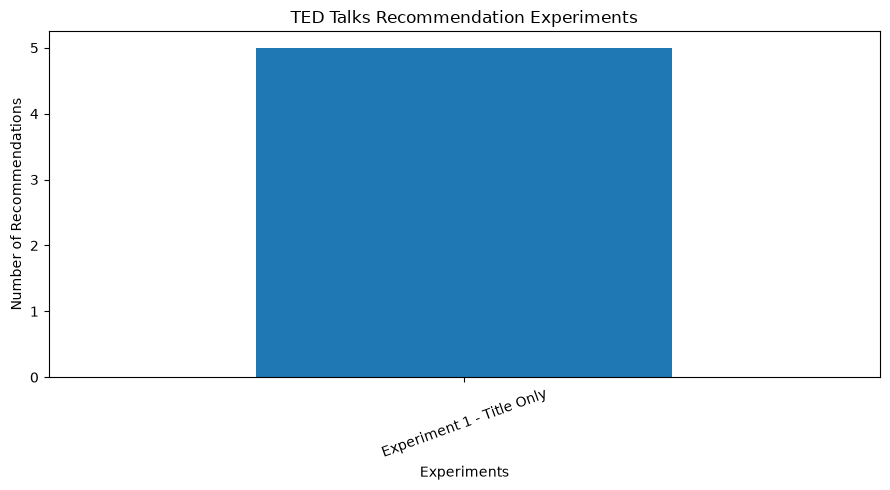

In [38]:
import matplotlib.pyplot as plt

experiment_counts = comparison_df["Experiment"].value_counts()

experiment_counts.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("TED Talks Recommendation Experiments")
plt.xlabel("Experiments")
plt.ylabel("Number of Recommendations")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

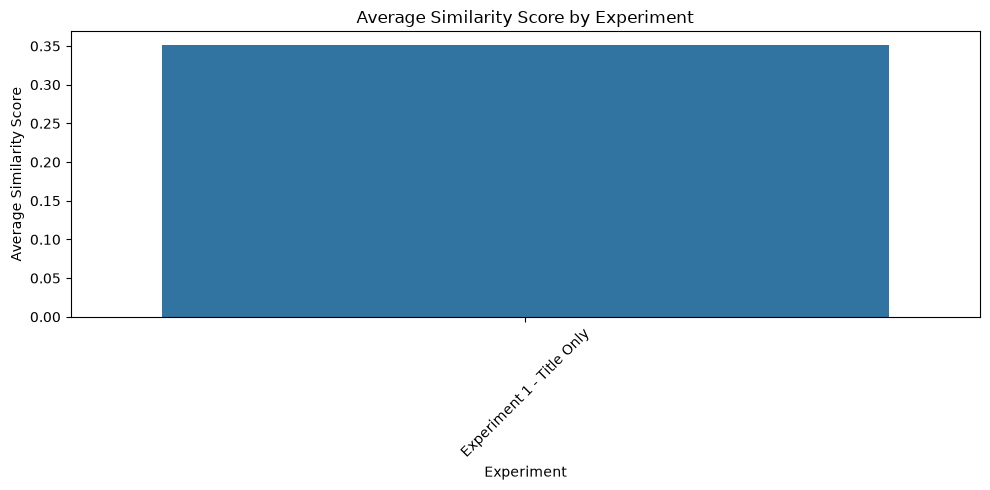

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.barplot(
    data=score_summary,
    x="Experiment",
    y="Average Similarity Score"
)

plt.title("Average Similarity Score by Experiment")
plt.xlabel("Experiment")
plt.ylabel("Average Similarity Score")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [46]:
comparison_df.to_csv(
    "task6_recommendation_results.csv",
    index=False
)

print("Results saved successfully!")

Results saved successfully!
